# Experiment 9: Markov Model and Reinforcement Learning

**Name:** Aditya Gaur  
**Roll Number:** U23AI095  
**College:** Sardar Vallabhbhai National Institute of Technology (SVNIT), Surat  
**Course/Lab:** AI401 — Intelligent Multi-Agent and Expert Systems

## Aim
To understand Markov models and implement basic reinforcement-learning techniques using Python.

This notebook follows all six exercises in the assignment. A small stochastic grid-world is used throughout so the Markov transition model and the reinforcement-learning experiments can be compared using the same states and actions.

### Environment used in this experiment
- The world is a 4 × 4 grid.
- The agent starts at the top-left cell, **S = (0, 0)**.
- The goal is at the bottom-right cell, **G = (3, 3)**.
- The pit is at **P = (2, 2)** and ends the episode if entered.
- Available actions are **Up, Right, Down, Left**.
- Movement is stochastic: with probability 0.80 the intended move occurs; with probability 0.10 the agent slips to either perpendicular direction. At an edge, a move that would leave the grid keeps the agent in the same cell.
- The base reward is −1 per ordinary move, +10 for reaching the goal, and −4 for entering the pit. The reward-modification exercise changes the pit penalty.

The assignment does not prescribe the exact states, transition probabilities, or reward values, so these are stated explicitly here to make the experiment reproducible. Random number generators use fixed seeds so the displayed results can be reproduced.

## 1. Imports and common environment functions

The code below defines the states, movement model, rewards, and helper functions used by the later exercises.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict

np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

GRID_SIZE = 4
START = (0, 0)
GOAL = (3, 3)
PIT = (2, 2)
ACTIONS = ["Up", "Right", "Down", "Left"]
ACTION_DELTAS = [(-1, 0), (0, 1), (1, 0), (0, -1)]
ACTION_SYMBOLS = {0: "↑", 1: "→", 2: "↓", 3: "←"}
MOVE_PROB = 0.80
SLIP_PROB = 0.10
BASE_REWARDS = {"step": -1.0, "goal": 10.0, "pit": -4.0}
MAX_STEPS = 60

ALL_STATES = [(r, c) for r in range(GRID_SIZE) for c in range(GRID_SIZE)]
STATE_TO_ID = {state: i for i, state in enumerate(ALL_STATES)}
ID_TO_STATE = {i: state for state, i in STATE_TO_ID.items()}
TERMINAL_STATES = {GOAL, PIT}


def move_from(state, action):
    """Apply a direction while keeping the agent inside the grid."""
    r, c = state
    dr, dc = ACTION_DELTAS[action]
    nr = min(max(r + dr, 0), GRID_SIZE - 1)
    nc = min(max(c + dc, 0), GRID_SIZE - 1)
    return (nr, nc)


def transition_distribution(state, action):
    """Return P(next_state | state, action), combining outcomes at boundaries."""
    if state in TERMINAL_STATES:
        return {state: 1.0}
    directions = [(action, MOVE_PROB), ((action - 1) % 4, SLIP_PROB), ((action + 1) % 4, SLIP_PROB)]
    distribution = defaultdict(float)
    for direction, probability in directions:
        distribution[move_from(state, direction)] += probability
    return dict(distribution)


def environment_step(state, action, rng, rewards=BASE_REWARDS):
    """Sample one transition and return next state, reward, and done flag."""
    if state in TERMINAL_STATES:
        return state, 0.0, True
    distribution = transition_distribution(state, action)
    next_states = list(distribution.keys())
    probabilities = list(distribution.values())
    next_state = next_states[int(rng.choice(len(next_states), p=probabilities))]
    if next_state == GOAL:
        reward = rewards["goal"]
        done = True
    elif next_state == PIT:
        reward = rewards["pit"]
        done = True
    else:
        reward = rewards["step"]
        done = False
    return next_state, reward, done


def random_episode(rng, max_steps=MAX_STEPS):
    """Run an episode where each action is selected uniformly at random."""
    state = START
    trajectory = [state]
    total_reward = 0.0
    terminal = "Step limit reached"
    for step_number in range(1, max_steps + 1):
        action = int(rng.integers(0, len(ACTIONS)))
        state, reward, done = environment_step(state, action, rng)
        trajectory.append(state)
        total_reward += reward
        if done:
            terminal = "Goal reached" if state == GOAL else "Pit reached"
            return trajectory, total_reward, step_number, terminal
    return trajectory, total_reward, max_steps, terminal


print("Grid size:", f"{GRID_SIZE} × {GRID_SIZE}")
print("Start:", START, " | Goal:", GOAL, " | Pit:", PIT)
print("Actions:", ", ".join(ACTIONS))
print("Transition probabilities: intended =", MOVE_PROB, ", each perpendicular slip =", SLIP_PROB)
print("Base rewards:", BASE_REWARDS)

Grid size: 4 × 4
Start: (0, 0)  | Goal: (3, 3)  | Pit: (2, 2)
Actions: Up, Right, Down, Left
Transition probabilities: intended = 0.8 , each perpendicular slip = 0.1
Base rewards: {'step': -1.0, 'goal': 10.0, 'pit': -4.0}


## 2. Exercise 1 — Markov Model

A Markov model describes transitions between states using probabilities. Here, the state is the agent's grid position. For this section the agent follows a **random policy** (each action has probability 0.25); the stochastic movement rules above determine the transition probabilities.

The transition matrix \(P\) contains entries \(P_{ij}=P(S_{t+1}=j\mid S_t=i)\). The goal and pit are absorbing states in the Markov chain: after the random-policy simulation reaches either terminal state, it remains there in the mathematical chain. The interactive environment itself ends an episode at that point.

In [2]:
# Build the state-to-state transition matrix under the random policy.
num_states = len(ALL_STATES)
P = np.zeros((num_states, num_states), dtype=float)

for state in ALL_STATES:
    i = STATE_TO_ID[state]
    if state in TERMINAL_STATES:
        P[i, i] = 1.0
        continue
    for action in range(len(ACTIONS)):
        for next_state, probability in transition_distribution(state, action).items():
            j = STATE_TO_ID[next_state]
            P[i, j] += (1.0 / len(ACTIONS)) * probability

transition_table = pd.DataFrame(
    P,
    index=[str(s) for s in ALL_STATES],
    columns=[str(s) for s in ALL_STATES]
)
print("Transition matrix P (rows = current state, columns = next state):")
display(transition_table.round(2))
print("Row sums (each should equal 1):", np.round(P.sum(axis=1), 6))

Transition matrix P (rows = current state, columns = next state):


,"(0, 0)","(0, 1)","(0, 2)","(0, 3)","(1, 0)","(1, 1)","(1, 2)","(1, 3)","(2, 0)","(2, 1)","(2, 2)","(2, 3)","(3, 0)","(3, 1)","(3, 2)","(3, 3)"
"(0, 0)",0.50,0.25,0.00,0.00,0.25,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
"(0, 1)",0.25,0.25,0.25,0.00,0.00,0.25,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
"(0, 2)",0.00,0.25,0.25,0.25,0.00,0.00,0.25,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
"(0, 3)",0.00,0.00,0.25,0.50,0.00,0.00,0.00,0.25,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
"(1, 0)",0.25,0.00,0.00,0.00,0.25,0.25,0.00,0.00,0.25,0.00,0.00,0.00,0.00,0.00,0.00,0.00
"(1, 1)",0.00,0.25,0.00,0.00,0.25,0.00,0.25,0.00,0.00,0.25,0.00,0.00,0.00,0.00,0.00,0.00
"(1, 2)",0.00,0.00,0.25,0.00,0.00,0.25,0.00,0.25,0.00,0.00,0.25,0.00,0.00,0.00,0.00,0.00
"(1, 3)",0.00,0.00,0.00,0.25,0.00,0.00,0.25,0.25,0.00,0.00,0.00,0.25,0.00,0.00,0.00,0.00
"(2, 0)",0.00,0.00,0.00,0.00,0.25,0.00,0.00,0.00,0.25,0.25,0.00,0.00,0.25,0.00,0.00,0.00
"(2, 1)",0.00,0.00,0.00,0.00,0.00,0.25,0.00,0.00,0.25,0.00,0.25,0.00,0.00,0.25,0.00,0.00


Row sums (each should equal 1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


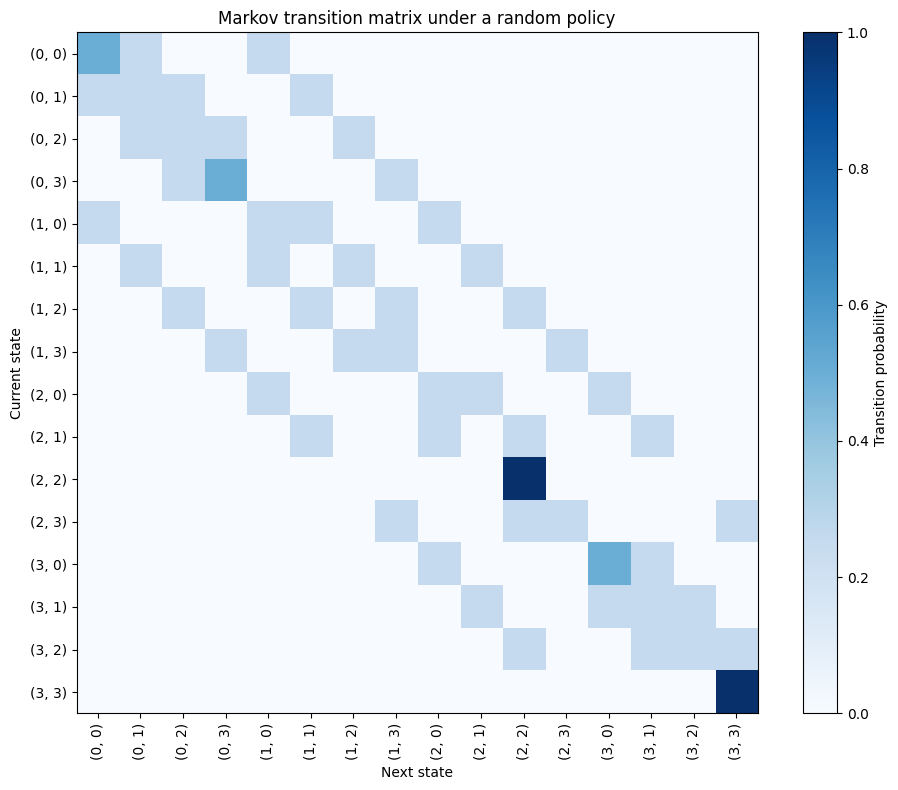

Random-policy simulation over 5,000 episodes:


,Measure,Result
0,Goal reached,0.1750
1,Pit reached,0.7598
2,Step limit reached,0.0652
3,Average episode length,24.7400
4,Average episode reward,-25.0944


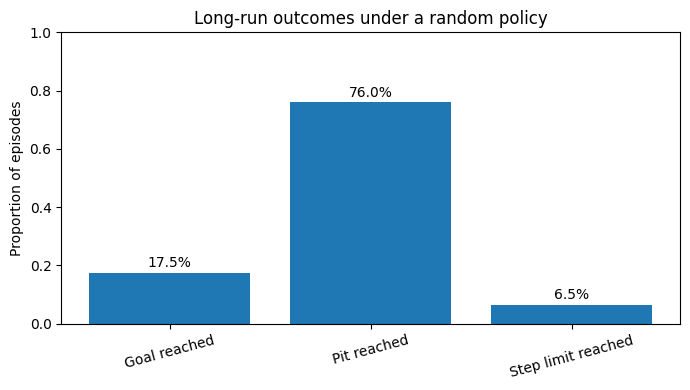

Example random trajectory:
(0, 0) -> (1, 0) -> (1, 0) -> (0, 0) -> (0, 0) -> (0, 0) -> (1, 0) -> (2, 0) -> (2, 1) -> (2, 2)
Outcome: Pit reached; steps: 9; total reward: -12.0


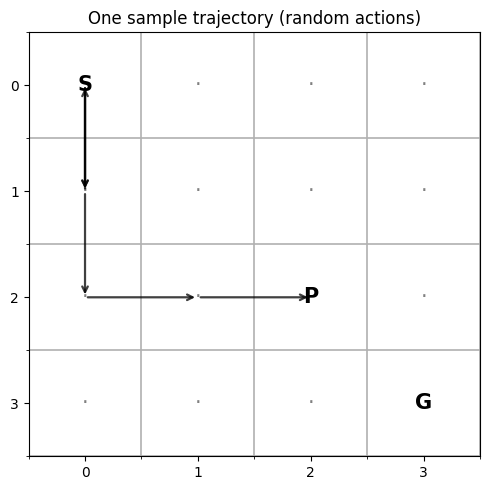

In [3]:
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(P, cmap="Blues", vmin=0, vmax=P.max())
ax.set_title("Markov transition matrix under a random policy")
ax.set_xlabel("Next state")
ax.set_ylabel("Current state")
state_labels = [f"{s}" for s in ALL_STATES]
ax.set_xticks(range(num_states), state_labels, rotation=90)
ax.set_yticks(range(num_states), state_labels)
fig.colorbar(image, ax=ax, label="Transition probability")
plt.tight_layout()
plt.show()

# Estimate long-run absorbing outcomes using repeated random-policy episodes.
markov_rng = np.random.default_rng(20261014)
num_simulations = 5000
markov_records = []
for _ in range(num_simulations):
    _, total_reward, steps, outcome = random_episode(markov_rng)
    markov_records.append((total_reward, steps, outcome))

markov_results = pd.DataFrame(markov_records, columns=["Total reward", "Steps", "Outcome"])
long_run_summary = pd.DataFrame({
    "Measure": ["Goal reached", "Pit reached", "Step limit reached", "Average episode length", "Average episode reward"],
    "Result": [
        (markov_results["Outcome"] == "Goal reached").mean(),
        (markov_results["Outcome"] == "Pit reached").mean(),
        (markov_results["Outcome"] == "Step limit reached").mean(),
        markov_results["Steps"].mean(),
        markov_results["Total reward"].mean(),
    ]
})
print(f"Random-policy simulation over {num_simulations:,} episodes:")
display(long_run_summary)

fig, ax = plt.subplots(figsize=(7, 4))
outcome_order = ["Goal reached", "Pit reached", "Step limit reached"]
outcome_rates = markov_results["Outcome"].value_counts(normalize=True).reindex(outcome_order, fill_value=0)
ax.bar(outcome_rates.index, outcome_rates.values)
ax.set_ylim(0, 1)
ax.set_ylabel("Proportion of episodes")
ax.set_title("Long-run outcomes under a random policy")
ax.tick_params(axis="x", rotation=15)
for i, value in enumerate(outcome_rates.values):
    ax.text(i, value + 0.02, f"{value:.1%}", ha="center")
plt.tight_layout()
plt.show()

# Show one example trajectory from a random policy.
trajectory, trajectory_reward, trajectory_steps, trajectory_outcome = random_episode(np.random.default_rng(41))
print("Example random trajectory:")
print(" -> ".join(map(str, trajectory)))
print(f"Outcome: {trajectory_outcome}; steps: {trajectory_steps}; total reward: {trajectory_reward:.1f}")

fig, ax = plt.subplots(figsize=(5, 5))
ax.set_xlim(-0.5, GRID_SIZE - 0.5)
ax.set_ylim(GRID_SIZE - 0.5, -0.5)
ax.set_xticks(np.arange(-0.5, GRID_SIZE, 1), minor=True)
ax.set_yticks(np.arange(-0.5, GRID_SIZE, 1), minor=True)
ax.grid(which="minor", linewidth=1.2)
ax.set_xticks(range(GRID_SIZE))
ax.set_yticks(range(GRID_SIZE))
for cell, label in [(START, "S"), (GOAL, "G"), (PIT, "P")]:
    ax.text(cell[1], cell[0], label, ha="center", va="center", fontsize=15, fontweight="bold")
for state in ALL_STATES:
    if state not in {START, GOAL, PIT}:
        ax.text(state[1], state[0], "·", ha="center", va="center", color="gray", fontsize=15)
for previous, current in zip(trajectory[:-1], trajectory[1:]):
    if previous != current:
        ax.annotate("", xy=(current[1], current[0]), xytext=(previous[1], previous[0]),
                    arrowprops={"arrowstyle": "->", "lw": 1.6, "alpha": 0.75})
ax.set_title("One sample trajectory (random actions)")
plt.tight_layout()
plt.show()

### Observation for Exercise 1

The transition matrix makes the Markov property explicit: the next-position distribution depends on the current position and chosen action, not on the earlier route. The random-policy experiment estimates how frequently the agent reaches the goal, falls into the pit, or uses the full step limit. Because movement includes random slips, one run can differ from another; the fixed seed makes these notebook results reproducible.

## 3. Exercise 2 — Reward-Based Decision-Making

Rewards tell the agent which outcomes are desirable. An ordinary move costs one point, the goal gives a positive reward, and the pit gives a penalty. To make the effect of the reward design visible, two agents are trained with the same movement model and training settings but different pit penalties:

- **Setting A:** pit penalty = −4
- **Setting B:** pit penalty = −20

A larger penalty makes entering the pit more costly. The learned policies and test metrics are compared below; a reward change can alter action values even when the final greedy route stays the same.

## 4. Exercise 3 — Q-Learning

Q-learning estimates \(Q(s,a)\), the expected discounted return from taking action \(a\) in state \(s\) and then following the learned policy. The update used here is

\[
Q(s,a) \leftarrow Q(s,a)+\alpha\big[r+\gamma\max_{a'}Q(s',a')-Q(s,a)\big]
\]

For a terminal transition, the future-value term is zero. The agent uses an \(\epsilon\)-greedy behaviour policy during training: it explores with probability \(\epsilon\) and otherwise chooses an action with the largest current Q-value.

Main Q-learning run: α = 0.15, γ = 0.95, initial ε = 0.30 (decays to 0.03)


,Episodes tested,Mean cumulative reward,Total cumulative reward,Mean steps,Success rate,Pit rate,Step-limit rate
0,500,1.448,724.0,7.088,0.824,0.176,0.0


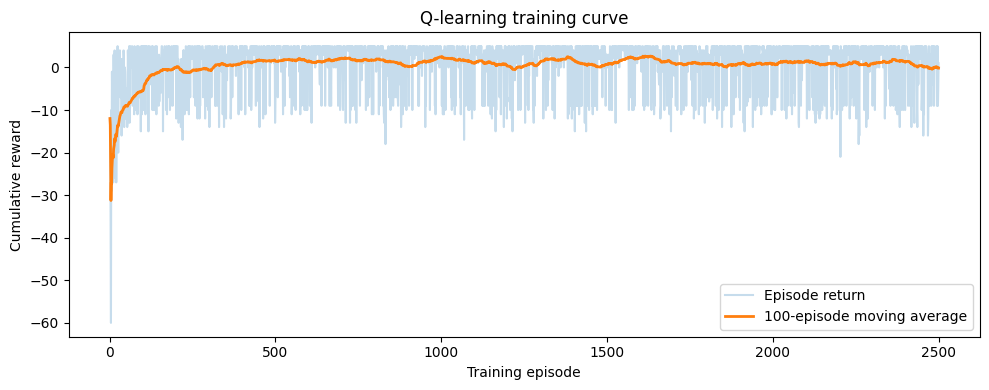

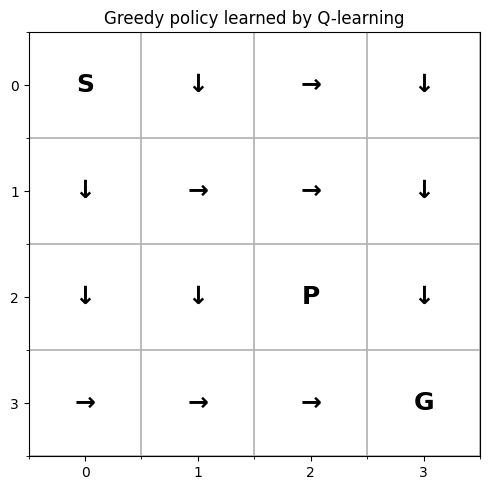

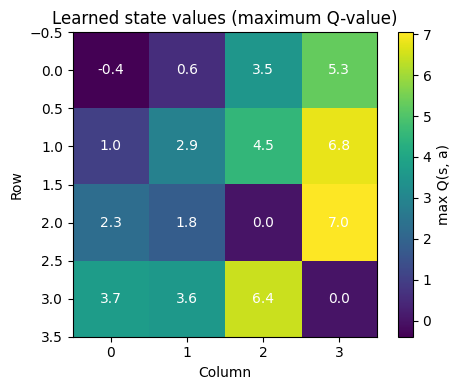

Learned Q-values by state and action:


,Up,Right,Down,Left
"(0, 0)",-0.94,-0.90,-0.39,-0.95
"(0, 1)",-1.52,-0.27,0.57,-0.92
"(0, 2)",-0.80,3.51,-1.61,-1.30
"(0, 3)",-0.32,-0.49,5.30,-0.28
"(1, 0)",-0.62,0.42,1.01,0.16
"(1, 1)",-0.56,2.87,0.68,0.19
"(1, 2)",0.27,4.53,-2.72,-0.52
"(1, 3)",1.41,2.39,6.79,0.25
"(2, 0)",0.80,1.00,2.28,0.69
"(2, 1)",0.68,-2.46,1.79,0.73


In [4]:
def train_q_learning(
    episodes=2000,
    alpha=0.15,
    gamma=0.95,
    epsilon=0.15,
    rewards=BASE_REWARDS,
    seed=0,
    decay_epsilon=False,
    min_epsilon=0.03,
    decay_rate=0.997,
    max_steps=MAX_STEPS,
):
    """Train a tabular Q-learning agent and return Q-values plus episode history."""
    rng = np.random.default_rng(seed)
    q_values = np.zeros((len(ALL_STATES), len(ACTIONS)), dtype=float)
    history = []

    for episode in range(episodes):
        state = START
        episode_return = 0.0
        reached_goal = False
        reached_pit = False
        if decay_epsilon:
            episode_epsilon = max(min_epsilon, epsilon * (decay_rate ** episode))
        else:
            episode_epsilon = epsilon

        for step_number in range(1, max_steps + 1):
            state_id = STATE_TO_ID[state]
            if rng.random() < episode_epsilon:
                action = int(rng.integers(0, len(ACTIONS)))
            else:
                best_actions = np.flatnonzero(np.isclose(q_values[state_id], q_values[state_id].max()))
                action = int(rng.choice(best_actions))

            next_state, reward, done = environment_step(state, action, rng, rewards)
            next_id = STATE_TO_ID[next_state]
            future_value = 0.0 if done else float(np.max(q_values[next_id]))
            target = reward + gamma * future_value
            q_values[state_id, action] += alpha * (target - q_values[state_id, action])
            episode_return += reward
            state = next_state

            if done:
                reached_goal = state == GOAL
                reached_pit = state == PIT
                break

        history.append({
            "episode": episode + 1,
            "return": episode_return,
            "steps": step_number,
            "goal": reached_goal,
            "pit": reached_pit,
            "epsilon": episode_epsilon,
        })

    return q_values, pd.DataFrame(history)


def greedy_action(q_values, state):
    """Return a greedy action, breaking ties consistently for display/evaluation."""
    return int(np.argmax(q_values[STATE_TO_ID[state]]))


def evaluate_policy(q_values, rewards=BASE_REWARDS, episodes=500, seed=1000, max_steps=MAX_STEPS):
    """Evaluate a greedy policy without exploratory actions."""
    rng = np.random.default_rng(seed)
    records = []
    for _ in range(episodes):
        state = START
        total_reward = 0.0
        outcome = "Step limit reached"
        for step_number in range(1, max_steps + 1):
            action = greedy_action(q_values, state)
            state, reward, done = environment_step(state, action, rng, rewards)
            total_reward += reward
            if done:
                outcome = "Goal reached" if state == GOAL else "Pit reached"
                break
        records.append({"return": total_reward, "steps": step_number, "outcome": outcome})
    results = pd.DataFrame(records)
    summary = {
        "Episodes tested": episodes,
        "Mean cumulative reward": results["return"].mean(),
        "Total cumulative reward": results["return"].sum(),
        "Mean steps": results["steps"].mean(),
        "Success rate": (results["outcome"] == "Goal reached").mean(),
        "Pit rate": (results["outcome"] == "Pit reached").mean(),
        "Step-limit rate": (results["outcome"] == "Step limit reached").mean(),
    }
    return summary, results


def display_policy(q_values, title):
    """Draw a learned policy as arrows on the grid."""
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.set_xlim(-0.5, GRID_SIZE - 0.5)
    ax.set_ylim(GRID_SIZE - 0.5, -0.5)
    ax.set_xticks(np.arange(-0.5, GRID_SIZE, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, GRID_SIZE, 1), minor=True)
    ax.grid(which="minor", linewidth=1.2)
    ax.set_xticks(range(GRID_SIZE))
    ax.set_yticks(range(GRID_SIZE))
    for state in ALL_STATES:
        if state == START:
            label = "S"
        elif state == GOAL:
            label = "G"
        elif state == PIT:
            label = "P"
        else:
            label = ACTION_SYMBOLS[greedy_action(q_values, state)]
        ax.text(state[1], state[0], label, ha="center", va="center", fontsize=18, fontweight="bold")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


def display_state_values(q_values, title):
    state_values = q_values.max(axis=1).reshape(GRID_SIZE, GRID_SIZE)
    fig, ax = plt.subplots(figsize=(5, 4))
    image = ax.imshow(state_values, cmap="viridis")
    for r in range(GRID_SIZE):
        for c in range(GRID_SIZE):
            ax.text(c, r, f"{state_values[r, c]:.1f}", ha="center", va="center", color="white")
    ax.set_title(title)
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")
    fig.colorbar(image, ax=ax, label="max Q(s, a)")
    plt.tight_layout()
    plt.show()


main_q, main_history = train_q_learning(
    episodes=2500, alpha=0.15, gamma=0.95, epsilon=0.30,
    rewards=BASE_REWARDS, seed=2026, decay_epsilon=True,
    min_epsilon=0.03, decay_rate=0.997
)
main_summary, main_test_results = evaluate_policy(main_q, BASE_REWARDS, episodes=500, seed=9876)
print("Main Q-learning run: α = 0.15, γ = 0.95, initial ε = 0.30 (decays to 0.03)")
display(pd.DataFrame([main_summary]).round(3))

# Plot episode returns and a 100-episode rolling average.
rolling_return = main_history["return"].rolling(100, min_periods=1).mean()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(main_history["episode"], main_history["return"], alpha=0.25, label="Episode return")
ax.plot(main_history["episode"], rolling_return, linewidth=2, label="100-episode moving average")
ax.set_xlabel("Training episode")
ax.set_ylabel("Cumulative reward")
ax.set_title("Q-learning training curve")
ax.legend()
plt.tight_layout()
plt.show()

display_policy(main_q, "Greedy policy learned by Q-learning")
display_state_values(main_q, "Learned state values (maximum Q-value)")

q_table = pd.DataFrame(main_q, index=[str(s) for s in ALL_STATES], columns=ACTIONS)
print("Learned Q-values by state and action:")
display(q_table.round(2))

### Observations for Exercises 2 and 3

The policy arrows show the greedy action selected from the learned Q-values. The learning curve is noisy because transitions are stochastic, so the moving average is useful for seeing the broader trend. The Q-value heatmap indicates which states the agent estimates to be more valuable under the chosen rewards and discount factor.

## 5. Exercise 2 — Effect of changing a reward

The same Q-learning method is run twice, changing only the penalty for entering the pit. Evaluation is carried out with greedy actions, while the environment itself remains stochastic.

Greedy-policy evaluation after changing the pit reward:


,Episodes tested,Mean cumulative reward,Total cumulative reward,Mean steps,Success rate,Pit rate,Step-limit rate
Reward setting,,,,,,,
Pit penalty −4,400,1.748,699.0,7.082,0.845,0.155,0.00
Pit penalty −20,400,-11.942,-4777.0,19.382,0.875,0.115,0.01


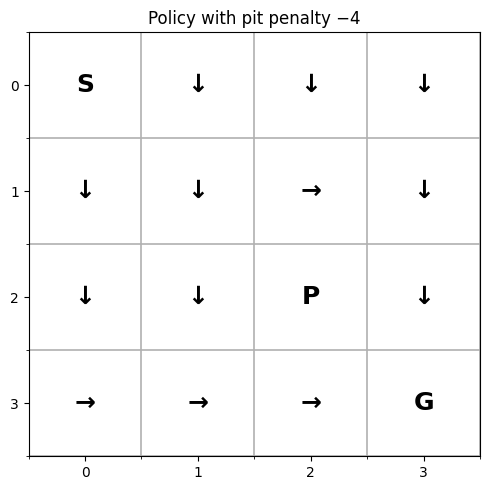

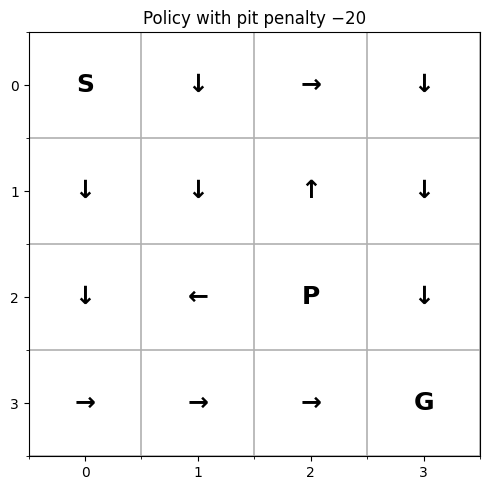

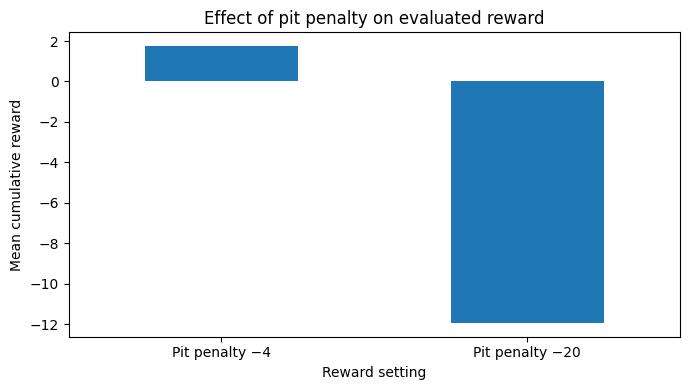

In [5]:
reward_settings = {
    "Pit penalty −4": {"step": -1.0, "goal": 10.0, "pit": -4.0},
    "Pit penalty −20": {"step": -1.0, "goal": 10.0, "pit": -20.0},
}
reward_runs = {}
reward_rows = []
for idx, (setting, rewards) in enumerate(reward_settings.items()):
    q_values, history = train_q_learning(
        episodes=1800, alpha=0.15, gamma=0.95, epsilon=0.15,
        rewards=rewards, seed=730 + idx, decay_epsilon=False
    )
    summary, results = evaluate_policy(q_values, rewards, episodes=400, seed=1730 + idx)
    reward_runs[setting] = {"q": q_values, "history": history, "summary": summary, "results": results, "rewards": rewards}
    reward_rows.append({"Reward setting": setting, **summary})

reward_comparison = pd.DataFrame(reward_rows).set_index("Reward setting")
print("Greedy-policy evaluation after changing the pit reward:")
display(reward_comparison.round(3))
display_policy(reward_runs["Pit penalty −4"]["q"], "Policy with pit penalty −4")
display_policy(reward_runs["Pit penalty −20"]["q"], "Policy with pit penalty −20")

fig, ax = plt.subplots(figsize=(7, 4))
reward_comparison["Mean cumulative reward"].plot(kind="bar", ax=ax)
ax.set_ylabel("Mean cumulative reward")
ax.set_title("Effect of pit penalty on evaluated reward")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

Compare both the Q-values/policy and the evaluation table. A stronger pit penalty makes pit transitions contribute a more negative target during learning. Depending on stochastic slips and training history, the displayed policy may change in particular cells; even where the greedy actions remain the same, the learned values and measured returns can differ.

## 6. Exercise 4 — Exploration vs. exploitation

Exploration tries actions that may not currently look best; exploitation chooses the best-known action. The following experiment trains otherwise similar agents with fixed \(\epsilon\) values. Each learned policy is then evaluated **without exploration**, so the test results measure the policy learned rather than continued random action selection.

Exploration settings compared on 400 greedy test episodes:


,ε,Episodes tested,Mean cumulative reward,Total cumulative reward,Mean steps,Success rate,Pit rate,Step-limit rate
Exploration setting,,,,,,,,
ε = 0.05,0.05,400,0.652,261.0,7.022,0.762,0.238,0.0
ε = 0.20,0.20,400,2.110,844.0,7.070,0.870,0.130,0.0
ε = 0.50,0.50,400,1.825,730.0,6.970,0.842,0.158,0.0


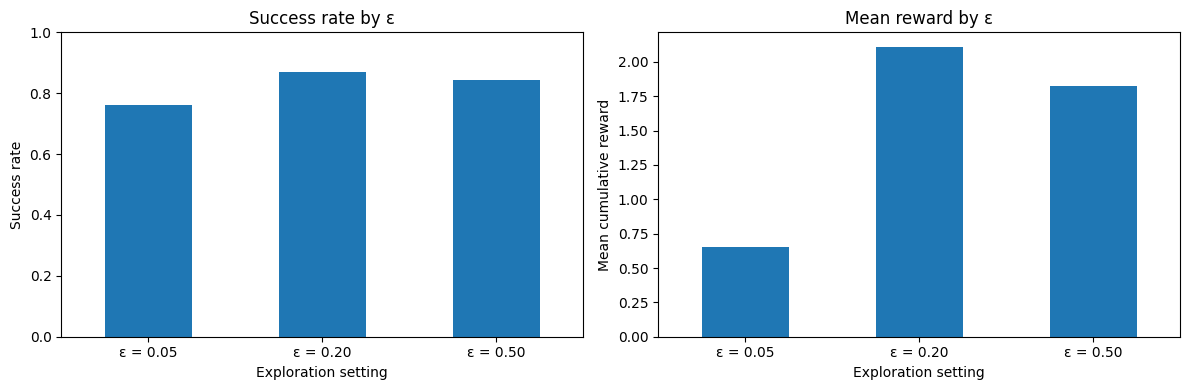

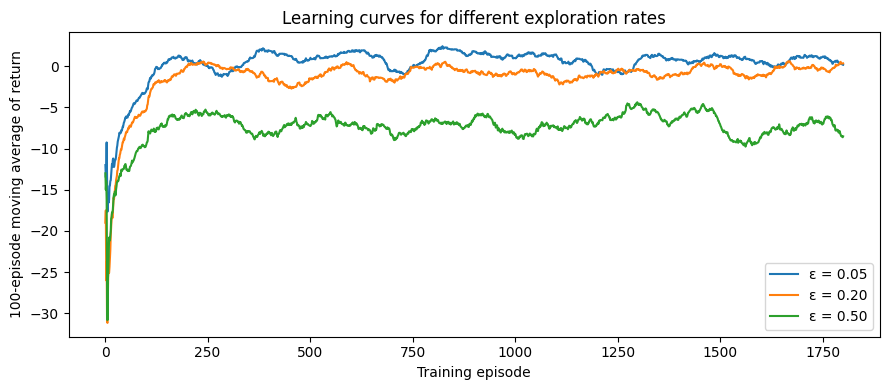

In [6]:
exploration_values = [0.05, 0.20, 0.50]
exploration_runs = {}
exploration_rows = []

for idx, epsilon_value in enumerate(exploration_values):
    q_values, history = train_q_learning(
        episodes=1800, alpha=0.15, gamma=0.95, epsilon=epsilon_value,
        rewards=BASE_REWARDS, seed=4100 + idx, decay_epsilon=False
    )
    summary, results = evaluate_policy(q_values, BASE_REWARDS, episodes=400, seed=5100 + idx)
    name = f"ε = {epsilon_value:.2f}"
    exploration_runs[name] = {"q": q_values, "history": history, "summary": summary, "results": results}
    exploration_rows.append({"Exploration setting": name, "ε": epsilon_value, **summary})

exploration_comparison = pd.DataFrame(exploration_rows).set_index("Exploration setting")
print("Exploration settings compared on 400 greedy test episodes:")
display(exploration_comparison.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
exploration_comparison["Success rate"].plot(kind="bar", ax=axes[0])
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Success rate")
axes[0].set_title("Success rate by ε")
axes[0].tick_params(axis="x", rotation=0)
exploration_comparison["Mean cumulative reward"].plot(kind="bar", ax=axes[1])
axes[1].set_ylabel("Mean cumulative reward")
axes[1].set_title("Mean reward by ε")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
for name, data in exploration_runs.items():
    smooth = data["history"]["return"].rolling(100, min_periods=1).mean()
    ax.plot(data["history"]["episode"], smooth, label=name)
ax.set_xlabel("Training episode")
ax.set_ylabel("100-episode moving average of return")
ax.set_title("Learning curves for different exploration rates")
ax.legend()
plt.tight_layout()
plt.show()

### Observation for Exercise 4

A very low \(\epsilon\) can limit early exploration, while a high value spends more training steps on random actions. A moderate value often provides a useful balance. The best setting should be chosen from the measured success rate, average return, and steps in this run rather than assumed in advance; results can vary with the seed and number of episodes.

## 7. Exercise 5 — Effect of the discount factor γ

The discount factor controls how strongly future rewards contribute to current Q-values. A lower value emphasizes near-term rewards; a value closer to 1 gives more weight to rewards received later. We train and test agents using the same reward setup and several values of \(\gamma\).

Discount-factor settings compared on 400 greedy test episodes:


,γ,Episodes tested,Mean cumulative reward,Total cumulative reward,Mean steps,Success rate,Pit rate,Step-limit rate
Discount setting,,,,,,,,
γ = 0.50,0.50,400,2.000,800.0,7.110,0.865,0.135,0.0
γ = 0.80,0.80,400,1.865,746.0,7.105,0.855,0.145,0.0
γ = 0.95,0.95,400,1.138,455.0,7.238,0.812,0.188,0.0
γ = 0.99,0.99,400,1.730,692.0,7.135,0.848,0.152,0.0


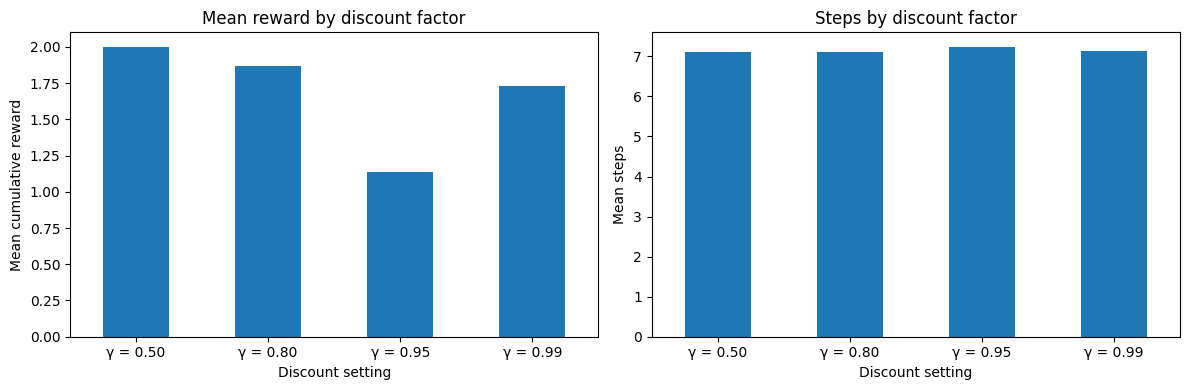

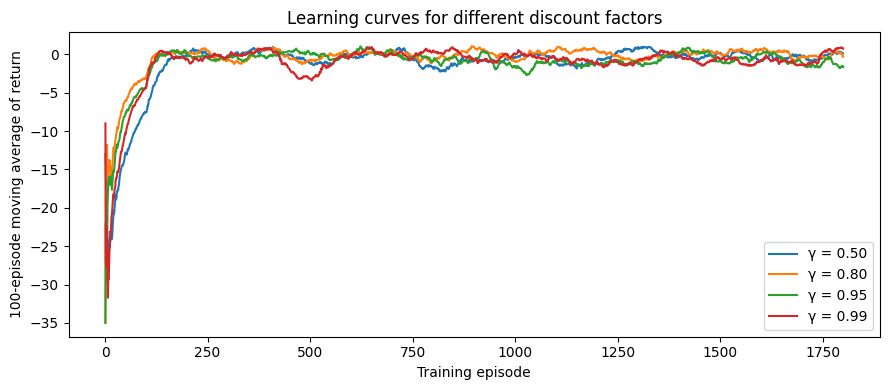

In [7]:
gamma_values = [0.50, 0.80, 0.95, 0.99]
gamma_runs = {}
gamma_rows = []

for idx, gamma_value in enumerate(gamma_values):
    q_values, history = train_q_learning(
        episodes=1800, alpha=0.15, gamma=gamma_value, epsilon=0.15,
        rewards=BASE_REWARDS, seed=6200 + idx, decay_epsilon=False
    )
    summary, results = evaluate_policy(q_values, BASE_REWARDS, episodes=400, seed=7200 + idx)
    name = f"γ = {gamma_value:.2f}"
    gamma_runs[name] = {"q": q_values, "history": history, "summary": summary, "results": results}
    gamma_rows.append({"Discount setting": name, "γ": gamma_value, **summary})

gamma_comparison = pd.DataFrame(gamma_rows).set_index("Discount setting")
print("Discount-factor settings compared on 400 greedy test episodes:")
display(gamma_comparison.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
gamma_comparison["Mean cumulative reward"].plot(kind="bar", ax=axes[0])
axes[0].set_ylabel("Mean cumulative reward")
axes[0].set_title("Mean reward by discount factor")
axes[0].tick_params(axis="x", rotation=0)
gamma_comparison["Mean steps"].plot(kind="bar", ax=axes[1])
axes[1].set_ylabel("Mean steps")
axes[1].set_title("Steps by discount factor")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
for name, data in gamma_runs.items():
    smooth = data["history"]["return"].rolling(100, min_periods=1).mean()
    ax.plot(data["history"]["episode"], smooth, label=name)
ax.set_xlabel("Training episode")
ax.set_ylabel("100-episode moving average of return")
ax.set_title("Learning curves for different discount factors")
ax.legend()
plt.tight_layout()
plt.show()

### Observation for Exercise 5

Compare each γ setting using the evaluation table and plots. The discount factor changes the balance between immediate movement costs and later terminal rewards. With a small grid, different γ values can still learn the same shortest sensible route, so similar success rates do not mean γ had no effect; Q-values and learning curves can still differ.

## 8. Exercise 6 — Policy Evaluation

Policy evaluation compares learned settings using the measures requested in the assignment: **cumulative rewards, steps taken, and success rate**. The table below brings together the main decaying-ε agent, reward changes, exploration settings, and discount-factor settings. “Mean cumulative reward” is the average return per test episode; “Total cumulative reward” is the sum over all test episodes. “Mean steps” is the average episode length.

Combined policy evaluation (greedy testing):


,Episodes tested,Mean cumulative reward,Total cumulative reward,Mean steps,Success rate,Pit rate,Step-limit rate
Experiment,,,,,,,
Main Q-learning (decaying ε),500,1.448,724.0,7.088,0.824,0.176,0.00
Pit penalty −4,400,1.748,699.0,7.082,0.845,0.155,0.00
Pit penalty −20,400,-11.942,-4777.0,19.382,0.875,0.115,0.01
Exploration ε = 0.05,400,0.652,261.0,7.022,0.762,0.238,0.00
Exploration ε = 0.20,400,2.110,844.0,7.070,0.870,0.130,0.00
Exploration ε = 0.50,400,1.825,730.0,6.970,0.842,0.158,0.00
Discount γ = 0.50,400,2.000,800.0,7.110,0.865,0.135,0.00
Discount γ = 0.80,400,1.865,746.0,7.105,0.855,0.145,0.00
Discount γ = 0.95,400,1.138,455.0,7.238,0.812,0.188,0.00


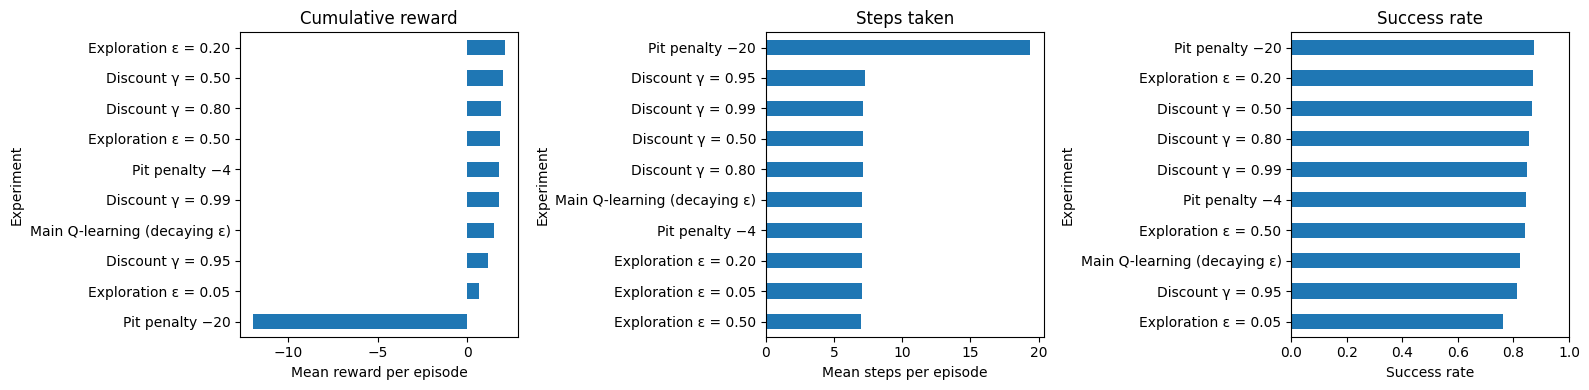

In [8]:
policy_rows = []
policy_rows.append({"Experiment": "Main Q-learning (decaying ε)", **main_summary})
for setting, data in reward_runs.items():
    policy_rows.append({"Experiment": setting, **data["summary"]})
for setting, data in exploration_runs.items():
    policy_rows.append({"Experiment": f"Exploration {setting}", **data["summary"]})
for setting, data in gamma_runs.items():
    policy_rows.append({"Experiment": f"Discount {setting}", **data["summary"]})

policy_evaluation = pd.DataFrame(policy_rows).set_index("Experiment")
print("Combined policy evaluation (greedy testing):")
display(policy_evaluation.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
policy_evaluation["Mean cumulative reward"].sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_xlabel("Mean reward per episode")
axes[0].set_title("Cumulative reward")
policy_evaluation["Mean steps"].sort_values().plot(kind="barh", ax=axes[1])
axes[1].set_xlabel("Mean steps per episode")
axes[1].set_title("Steps taken")
policy_evaluation["Success rate"].sort_values().plot(kind="barh", ax=axes[2])
axes[2].set_xlabel("Success rate")
axes[2].set_xlim(0, 1)
axes[2].set_title("Success rate")
plt.tight_layout()
plt.show()

## Overall observations and conclusion

1. **Markov model:** The transition matrix represents the probability of moving from each current state to each possible next state. The random-policy simulation shows the long-run mix of successful, pit, and unfinished episodes in this stochastic environment.
2. **Reward-based decisions:** Rewards define what the agent is trying to maximize. A more severe pit penalty makes the pit less desirable and changes the Q-learning targets.
3. **Q-learning:** The agent learns action values from sampled experience rather than being given the optimal route. The Q-table, state-value heatmap, greedy-policy arrows, and training curve provide different views of the learned result.
4. **Exploration vs. exploitation:** Low ε uses learned actions more often but may explore less; high ε explores more but also introduces more random actions while learning. Test metrics provide a practical way to compare the settings.
5. **Discount factor:** γ affects the relative importance of near-term and future reward. Its effect can appear in Q-values and learning progress even if policies have similar test performance.
6. **Policy evaluation:** Cumulative reward, steps taken, and success rate should be considered together. A setting with the highest average reward is not automatically the one with the shortest episodes, and estimates are affected by stochastic transitions.

The experiments illustrate how a Markov transition model describes the environment and how reward-based Q-learning can use that model's sampled transitions to learn a policy. The numerical results are specific to the stated grid, probabilities, rewards, training length, evaluation length, and random seeds.